<a href="https://colab.research.google.com/github/pabloisai2199-ia/REDES-NEURONALES-ARTIFICIALES/blob/main/01_06_entrenamiento_PABLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrenamiento de una red neuronal

Ejercicio (6 puntos posibles)

Al entrenar una red buscamos que ésta tenga un comportamiendo presumiblemente adecuado y observable en un conjunto de datos. Es decír a partir de los ejemplos esperamos que la red aprenda una función $f$ tal que la salida de la red imite el patrón en los datos. En nuestro caso, al utilizar el conjunto de entrenamiento MNIST esperamos que la función aprendida provea como salida el número al cual corresponde la imagen de entrada.

En este notebook implementaremos el descenso por gradiente usnado pytorch para entrenar la red que ya codificamos en el ejercicio anterior. Consideramos que que nuesto notebook es correcto si es que mejoramos el desempeño de la red previo a que sea entrenada.

Como ejemplo tenemos la figura siguiente, donde la entrada es una imagen en escala de grises y la salida es la clase '4' donde observamos que esa locación tiene la mayor probabilidad.

<img src="https://github.com/irvingvasquez/practicas_pytorch/blob/master/archivos/function_approx.png?raw=1">

Imagen tomada de [1]

Instrucciones: completa el código donde aparece *TODO:* (Hacer en inglés)



Si ejecutas en COLAB debes copiar los archivos extra de este repositorio.

@juan1rving

## Retropropagación y Autograd

Pytorch provee el módulo *autograd* para calcular los gradientes, y si!, nos evita estar calculando las derivadas! Esto lo realiza a partir de mantener en la vista todas las operaciones que se ejecutan sobre los tensores.

Si deseas asegurarte que autograd siga a un tensor especificamos *requires_grad*. Esto se puede hacer en la creación o en cualquier momento.

Veamos el siguiente código de ejemplo:

```python
# especificamos que la variable x es seguida por autograd
x = torch.zeros(1, requires_grad=True)
# si en algún momento desamos que temporalmente se deje de seguir el tensor usamos
>>> with torch.no_grad():
...     y = x * 2
# establecemos de nuevo el seguimiento
>>> y.requires_grad
```

Si queremos eliminar autograd de todos los tensores usamos `torch.set_grad_enabled(True|False)`.

Ahora bien, para calcular los gradientes simplemente usamos el método *backward()*. Por ejemplo para un tensor *cualquiera* hacemos *z.backward()*

Veamos a continuación el uso del gradiente.

In [2]:
# importamos paquetes
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from collections import OrderedDict

import numpy as np
import time

import torch
from torch import nn
from torch import optim
import torch.nn.functional as F

import helper

In [3]:
# especificamos que el tensor x es seguido por autograd
x = torch.randn(4, requires_grad=True)
print(x)

tensor([-0.3171,  0.8299, -0.0762, -1.4148], requires_grad=True)


In [4]:
# generamos un nuevo tensor a partir de x
# por ejemplo elevemos al cuadrado la variable x
y = x**2
print(y)

tensor([0.1006, 0.6887, 0.0058, 2.0016], grad_fn=<PowBackward0>)


In [5]:
## con grad_fn observamos la operación que generó y, es decir una operación potencia (pow)
print(y.grad_fn)


In [6]:
# De esta forma es posible saber las operaciónes que generan cada tensor, y por tanto, es posible calcular el gradiente.
# Hagamos ahora una operación de media
z = y.mean()
print(z)

tensor(0.6992, grad_fn=<MeanBackward0>)


In [7]:
# hasta este momento los gradientes son cero
print(x.grad)

None


Para calcular los gradientes es necesario llamar al método *.backward* sobre la variable. Supongamos sobre *z*. Esto calcula el gradiente de z con respecto de x.

El gradiente analítico de las operaciónes que hicimos es:
$$
\frac{\partial z}{\partial x} = \frac{\partial}{\partial x}\left[\frac{1}{n}\sum_i^n x_i^2\right] = \frac{x}{2}
$$

Ahora comprobemos

In [8]:
z.backward()
print(x.grad)

print(x/2)

tensor([-0.1586,  0.4149, -0.0381, -0.7074])
tensor([-0.1586,  0.4149, -0.0381, -0.7074], grad_fn=<DivBackward0>)


## Conjunto de datos y red neuronal

Ahora descargemos los datos y generemos una red tal cual lo vimos en el notebook anterior.

In [9]:
from torchvision import datasets, transforms

# Define a transform to normalize the data
transform = transforms.Compose([transforms.ToTensor(),
                                #transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
                                transforms.Normalize([0.5],[0.5])
                             ])
# Download and load the training data
trainset = datasets.MNIST('MNIST_data/', download=True, train=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 23.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 617kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.47MB/s]


In [10]:
# Hyperparameters for our network
input_size = 784
hidden_sizes = [128, 64]
output_size = 10

# Build a feed-forward network
model = nn.Sequential(OrderedDict([
                      ('fc1', nn.Linear(input_size, hidden_sizes[0])),
                      ('relu1', nn.ReLU()),
                      ('fc2', nn.Linear(hidden_sizes[0], hidden_sizes[1])),
                      ('relu2', nn.ReLU()),
                      ('logits', nn.Linear(hidden_sizes[1], output_size))]))

# NOTA solo calcularemos los logits y definiremos la perdida a partir de ellos

## Entrenamiento de la red

Lo primero que definiremos será la función de pérdida (loss) que es nombrada en pytorch como **criterion**. En este ejemplo estamos utilizando softmax, asi que definimos el criterio como
```
criterion = nn.CrossEntropyLoss()
```
Más tarde, en el entrenamiento, veremos que *loss = criterion(output, targets)* calcula la pérdida.

Lo segundo que definiremos será el optimizador, para este ejemplo usaremos SGD (stochastic gradient descent). Simplemente llamamos a *torch.optim.SGD* y le pasamos los parámetros de la red y el learning rate. La instrucción implementada se verá algo como lo siguiente:
```
optimizer = optim.SGD(model.parameters(), lr=0.01)
```

In [11]:
# TODO: Define la pérdida (1 punto)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

Antes de realizar el entrenamiento completo haremos un paso del aprendizaje. Este paso se compone de las siguientes tareas:

1. Realizar un pase frontal de la red
2. Utilizar los logits para calcular la pérdida
3. Realizar la retropropagación para calcular los gradientes.
4. Actualizar los pesos usando el optimizador.

Veamos el ejemplo


In [12]:
print('Initial weights - ', model.fc1.weight)


Initial weights -  Parameter containing:
tensor([[ 0.0021,  0.0341,  0.0144,  ..., -0.0211, -0.0107, -0.0034],
        [ 0.0065, -0.0303,  0.0301,  ..., -0.0106, -0.0222, -0.0139],
        [ 0.0102,  0.0288,  0.0137,  ..., -0.0353, -0.0226, -0.0136],
        ...,
        [-0.0018,  0.0332,  0.0276,  ...,  0.0221, -0.0212,  0.0187],
        [ 0.0081,  0.0303, -0.0331,  ...,  0.0047,  0.0112,  0.0164],
        [-0.0302, -0.0037, -0.0068,  ..., -0.0245,  0.0053,  0.0212]],
       requires_grad=True)


In [13]:
images, labels = next(iter(trainloader))
images.resize_(64, 784)

# Limpiar los gradientes por que se acumulan
optimizer.zero_grad()

# Pase hacia adelante
output = model.forward(images)
# Perdida
loss = criterion(output, labels)
# Pase de reversa
loss.backward()
print('Gradient -', model.fc1.weight.grad)
# Actualiza los pesos de acuerdo a un paso del optimizador
optimizer.step()

Gradient - tensor([[-0.0024, -0.0024, -0.0024,  ..., -0.0024, -0.0024, -0.0024],
        [-0.0003, -0.0003, -0.0003,  ..., -0.0003, -0.0003, -0.0003],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [ 0.0019,  0.0019,  0.0019,  ...,  0.0019,  0.0019,  0.0019],
        [ 0.0016,  0.0016,  0.0016,  ...,  0.0016,  0.0016,  0.0016],
        [ 0.0037,  0.0037,  0.0037,  ...,  0.0037,  0.0037,  0.0037]])


In [14]:
print('Updated weights - ', model.fc1.weight)

Updated weights -  Parameter containing:
tensor([[ 0.0021,  0.0341,  0.0144,  ..., -0.0210, -0.0107, -0.0033],
        [ 0.0065, -0.0303,  0.0301,  ..., -0.0106, -0.0222, -0.0139],
        [ 0.0102,  0.0288,  0.0137,  ..., -0.0353, -0.0226, -0.0136],
        ...,
        [-0.0018,  0.0331,  0.0276,  ...,  0.0220, -0.0212,  0.0186],
        [ 0.0081,  0.0303, -0.0331,  ...,  0.0047,  0.0112,  0.0164],
        [-0.0302, -0.0037, -0.0068,  ..., -0.0245,  0.0053,  0.0211]],
       requires_grad=True)


## Entrenamiento por épocas

Ahora si, entrenemos la red por varias épocas. Para ello programaremos el algoritmo de descenso por gradiente. De forma general éste funciona como sigue:

- Para un número de *épocas*:
    - Para cada *lote* en el conjunto de datos:
        - Aplanar las imágenes para que tengan el formato correcto (784 características)
        - Reiniciar los gradientes acumulados usando `optimizer.zero_grad()`
        - **Pase frontal**: La red predice usando el *lote* de imágenes
        - **Calcular pérdida**: Estimar la *pérdida* a partir de la *salida* y de las *etiquetas* reales usando el criterio definido
        - **Retropropagación**: Calcular los gradientes llamando `loss.backward()`
        - **Actualizar pesos**: Usar el optimizador para actualizar los parámetros con `optimizer.step()`
        - Monitorear el progreso imprimiendo la pérdida cada cierto número de pasos

Este proceso iterativo permite que la red aprenda gradualmente a clasificar correctamente los dígitos del conjunto MNIST, minimizando la función de pérdida en cada época.
        
    

In [15]:
# hiperparámetros
# número de épocas
epochs = 5
tasa_de_aprendizaje = 0.003

## Optimizador

El **optimizador** es el algoritmo responsable de actualizar los pesos de la red neuronal durante el entrenamiento. Su función principal es minimizar la función de pérdida ajustando los parámetros del modelo en la dirección que reduce el error.

### Función del optimizador:
- **Actualización de pesos**: Modifica los parámetros de la red basándose en los gradientes calculados durante la retropropagación
- **Control del aprendizaje**: Determina qué tan grandes son los pasos que da el modelo hacia el mínimo de la función de pérdida
- **Convergencia**: Ayuda a que el modelo converja hacia una solución óptima

### Ejemplo: Selección del SGD (Stochastic Gradient Descent)

El SGD es uno de los optimizadores más básicos y efectivos. Se selecciona de la siguiente manera:

```python
# Definir el optimizador SGD
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
```

**Parámetros importantes:**
- `model.parameters()`: Los pesos de la red que serán actualizados
- `lr` (learning rate): Controla el tamaño del paso en cada actualización
- `momentum`: Ayuda a acelerar la convergencia y evitar mínimos locales

**Ventajas del SGD:**
- Simple y computacionalmente eficiente
- Funciona bien en la mayoría de problemas
- Menos propenso al sobreajuste comparado con optimizadores más complejos

In [16]:
# TODO: redefine la configuración del optimizador usando la tasa de aprendizaje objetivo (1 punto)
optimizer = optim.SGD(model.parameters(), lr=tasa_de_aprendizaje, momentum=0.9)

In [17]:
#TODO: Completa el código para entrenar la red (4 puntos)
print_every = 40
steps = 0

for e in range(epochs):
    running_loss = 0
    # en cada iteración del for cargamos un batch
    for images, labels in iter(trainloader):
        steps += 1
        # Aplanar las imagenes de MNIST
        images.resize_(images.size()[0], 784)

        # Reiniciar el gradiente
        optimizer.zero_grad()

        # TODO: Pase frontal de la red
        output = model(images)

        # TODO: Estimar la perdida
        loss = criterion(output, labels)

        # TODO: Backprogation
        loss.backward()

        # TODO: Actualizamos los pesos
        optimizer.step()


        # Guardamos la perdida para control del entrenamiento
        running_loss += loss.item()

        # imprimimos cada 40 lotes
        if steps % print_every == 0:
            print("Epoch: {}/{}... ".format(e+1, epochs),
                  "Loss: {:.4f}".format(running_loss/print_every))

            running_loss = 0

Epoch: 1/5...  Loss: 2.2513
Epoch: 1/5...  Loss: 2.0315
Epoch: 1/5...  Loss: 1.5451
Epoch: 1/5...  Loss: 1.0389
Epoch: 1/5...  Loss: 0.7805
Epoch: 1/5...  Loss: 0.6194
Epoch: 1/5...  Loss: 0.5719
Epoch: 1/5...  Loss: 0.4881
Epoch: 1/5...  Loss: 0.4742
Epoch: 1/5...  Loss: 0.4389
Epoch: 1/5...  Loss: 0.4410
Epoch: 1/5...  Loss: 0.4185
Epoch: 1/5...  Loss: 0.3907
Epoch: 1/5...  Loss: 0.3798
Epoch: 1/5...  Loss: 0.3781
Epoch: 1/5...  Loss: 0.3656
Epoch: 1/5...  Loss: 0.3728
Epoch: 1/5...  Loss: 0.3750
Epoch: 1/5...  Loss: 0.3282
Epoch: 1/5...  Loss: 0.3594
Epoch: 1/5...  Loss: 0.3601
Epoch: 1/5...  Loss: 0.3403
Epoch: 1/5...  Loss: 0.3316
Epoch: 2/5...  Loss: 0.1578
Epoch: 2/5...  Loss: 0.3081
Epoch: 2/5...  Loss: 0.3214
Epoch: 2/5...  Loss: 0.3051
Epoch: 2/5...  Loss: 0.2971
Epoch: 2/5...  Loss: 0.3096
Epoch: 2/5...  Loss: 0.2890
Epoch: 2/5...  Loss: 0.3334
Epoch: 2/5...  Loss: 0.2933
Epoch: 2/5...  Loss: 0.3339
Epoch: 2/5...  Loss: 0.3097
Epoch: 2/5...  Loss: 0.2975
Epoch: 2/5...  Loss:

En este notebook, solo nos estamos fijando en la pérdida. Para considerar que el ejercicio es válido debemos mostrar que la pérdida va disminuyendo conforme avanzan las épocas. Finalmente, veamos que tan bien está clasificando la red con un ejemplo aleatorio. ¿Está haciendo predicciónes correctas?


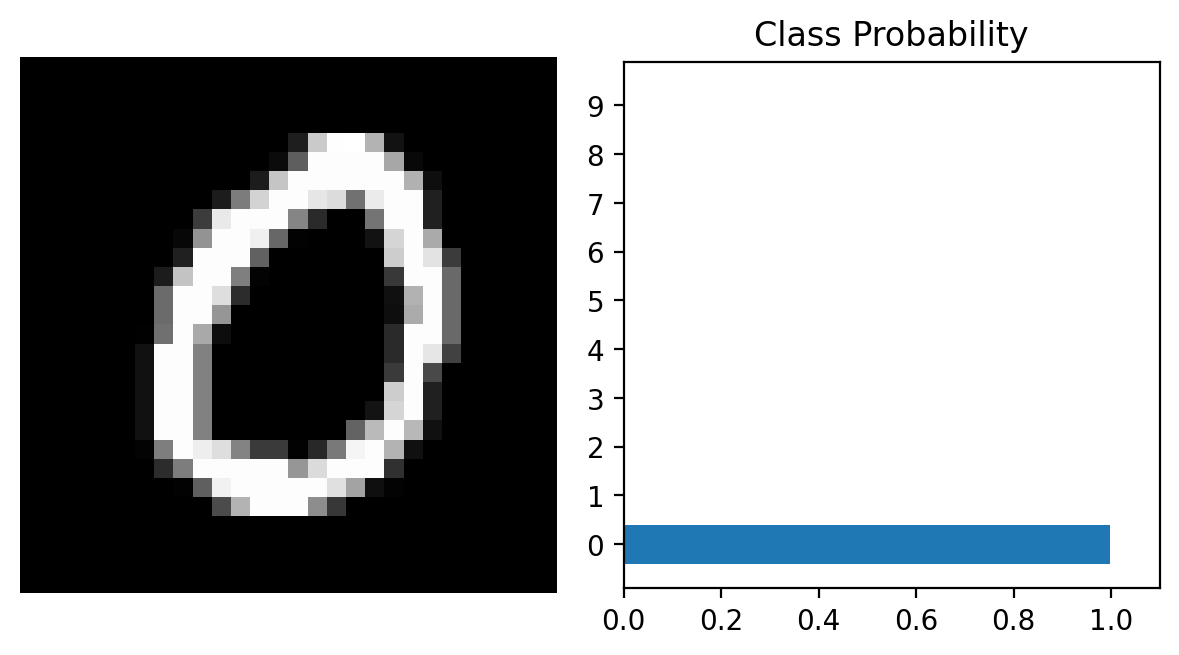

In [19]:
import matplotlib.pyplot as plt
import numpy as np

def view_classify(img, ps, version="MNIST"):
    ''' Muestra una imagen y la distribución de probabilidades predichas. '''
    ps = ps.data.numpy().squeeze()
    img = img.data.numpy().squeeze()

    fig, (ax1, ax2) = plt.subplots(figsize=(6, 9), ncols=2)

    ax1.imshow(img, cmap='gray')
    ax1.axis('off')

    ax2.barh(np.arange(10), ps)
    ax2.set_aspect(0.1)
    ax2.set_yticks(np.arange(10))
    if version == "MNIST":
        ax2.set_yticklabels(np.arange(10))
    elif version == "Fashion":
        ax2.set_yticklabels(
            ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
             'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot'],
            size='small')
    ax2.set_title('Class Probability')
    ax2.set_xlim(0, 1.1)

    plt.tight_layout()
    plt.show()


images, labels = next(iter(trainloader))

img = images[0].view(1, 784)
# Turn off gradients to speed up this part
with torch.no_grad():
    logits = model.forward(img)

# Output of the network are logits, need to take softmax for probabilities
ps = F.softmax(logits, dim=1)
view_classify(img.view(1, 28, 28), ps)

## Requisitos de entrega

Para que puedan obtener los puntos completos deben cumplir con los siguientes requisitos:
- Alcanzar una pérdida menor a 0.1
- Mostrar la pérdida por época en una gráfica

## Referencias

[1] Udacity Computer Vision Nanodegree

[2] Pytorch https://pytorch.org/

Epoch: 1/5...  Loss: 0.1346
Epoch: 1/5...  Loss: 0.1360
Epoch: 1/5...  Loss: 0.1252
Epoch: 1/5...  Loss: 0.1554
Epoch: 1/5...  Loss: 0.1282
Epoch: 1/5...  Loss: 0.1529
Epoch: 1/5...  Loss: 0.1332
Epoch: 1/5...  Loss: 0.1240
Epoch: 1/5...  Loss: 0.1313
Epoch: 1/5...  Loss: 0.1106
Epoch: 1/5...  Loss: 0.1350
Epoch: 1/5...  Loss: 0.1338
Epoch: 1/5...  Loss: 0.1527
Epoch: 1/5...  Loss: 0.1192
Epoch: 1/5...  Loss: 0.1325
Epoch: 1/5...  Loss: 0.1200
Epoch: 1/5...  Loss: 0.1177
Epoch: 1/5...  Loss: 0.1224
Epoch: 1/5...  Loss: 0.1328
Epoch: 1/5...  Loss: 0.1261
Epoch: 1/5...  Loss: 0.1425
Epoch: 1/5...  Loss: 0.1124
Epoch: 1/5...  Loss: 0.1267
===== Epoch 1/5 — Loss media: 0.1301 =====
Epoch: 2/5...  Loss: 0.0537
Epoch: 2/5...  Loss: 0.1143
Epoch: 2/5...  Loss: 0.1338
Epoch: 2/5...  Loss: 0.1366
Epoch: 2/5...  Loss: 0.1059
Epoch: 2/5...  Loss: 0.1103
Epoch: 2/5...  Loss: 0.1271
Epoch: 2/5...  Loss: 0.1258
Epoch: 2/5...  Loss: 0.1162
Epoch: 2/5...  Loss: 0.1221
Epoch: 2/5...  Loss: 0.1030
Epoch

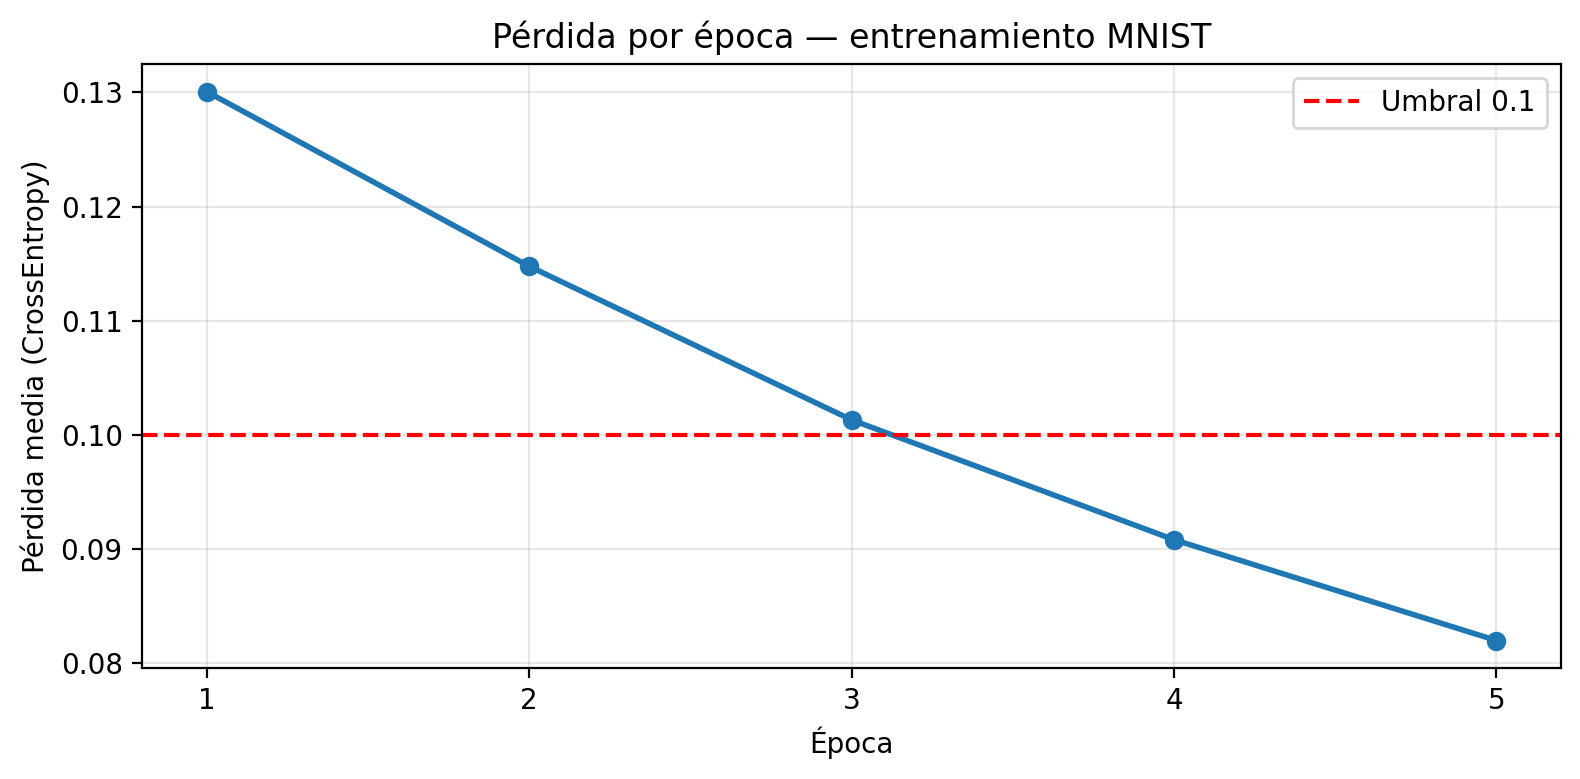

Pérdida final: 0.0820


In [20]:
import matplotlib.pyplot as plt

print_every = 40
steps = 0

# Listas para guardar la pérdida por época
epoch_losses = []

for e in range(epochs):
    running_loss = 0
    epoch_loss = 0
    n_batches = 0

    for images, labels in iter(trainloader):
        steps += 1
        n_batches += 1
        images.resize_(images.size()[0], 784)

        optimizer.zero_grad()

        # TODO: Pase frontal
        output = model(images)

        # TODO: Pérdida
        loss = criterion(output, labels)

        # TODO: Backpropagation
        loss.backward()

        # TODO: Actualizar pesos
        optimizer.step()

        running_loss += loss.item()
        epoch_loss += loss.item()

        if steps % print_every == 0:
            print("Epoch: {}/{}... ".format(e+1, epochs),
                  "Loss: {:.4f}".format(running_loss/print_every))
            running_loss = 0

    # Pérdida media de la época
    avg_epoch_loss = epoch_loss / n_batches
    epoch_losses.append(avg_epoch_loss)
    print(f"===== Epoch {e+1}/{epochs} — Loss media: {avg_epoch_loss:.4f} =====")

# Gráfica
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs+1), epoch_losses, marker='o', linewidth=2)
plt.xlabel('Época')
plt.ylabel('Pérdida media (CrossEntropy)')
plt.title('Pérdida por época — entrenamiento MNIST')
plt.grid(True, alpha=0.3)
plt.xticks(range(1, epochs+1))
plt.axhline(y=0.1, color='red', linestyle='--', label='Umbral 0.1')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Pérdida final: {epoch_losses[-1]:.4f}")

Epoch: 1/15...  Loss: 0.1049
Epoch: 1/15...  Loss: 0.1025
Epoch: 1/15...  Loss: 0.1326
Epoch: 1/15...  Loss: 0.1367
Epoch: 1/15...  Loss: 0.1154
Epoch: 1/15...  Loss: 0.1170
Epoch: 1/15...  Loss: 0.1232
Epoch: 1/15...  Loss: 0.1079
Epoch: 1/15...  Loss: 0.1176
Epoch: 1/15...  Loss: 0.1501
Epoch: 1/15...  Loss: 0.1128
Epoch: 1/15...  Loss: 0.1206
Epoch: 1/15...  Loss: 0.1093
Epoch: 1/15...  Loss: 0.1300
Epoch: 1/15...  Loss: 0.1112
Epoch: 1/15...  Loss: 0.1107
Epoch: 1/15...  Loss: 0.1368
Epoch: 1/15...  Loss: 0.1298
Epoch: 1/15...  Loss: 0.0969
Epoch: 1/15...  Loss: 0.1260
Epoch: 1/15...  Loss: 0.1056
Epoch: 1/15...  Loss: 0.1189
Epoch: 1/15...  Loss: 0.1228
===== Epoch 1/15 — Loss media: 0.1189 =====
Epoch: 2/15...  Loss: 0.0322
Epoch: 2/15...  Loss: 0.1057
Epoch: 2/15...  Loss: 0.1109
Epoch: 2/15...  Loss: 0.0847
Epoch: 2/15...  Loss: 0.0792
Epoch: 2/15...  Loss: 0.1128
Epoch: 2/15...  Loss: 0.1085
Epoch: 2/15...  Loss: 0.0948
Epoch: 2/15...  Loss: 0.0826
Epoch: 2/15...  Loss: 0.0943

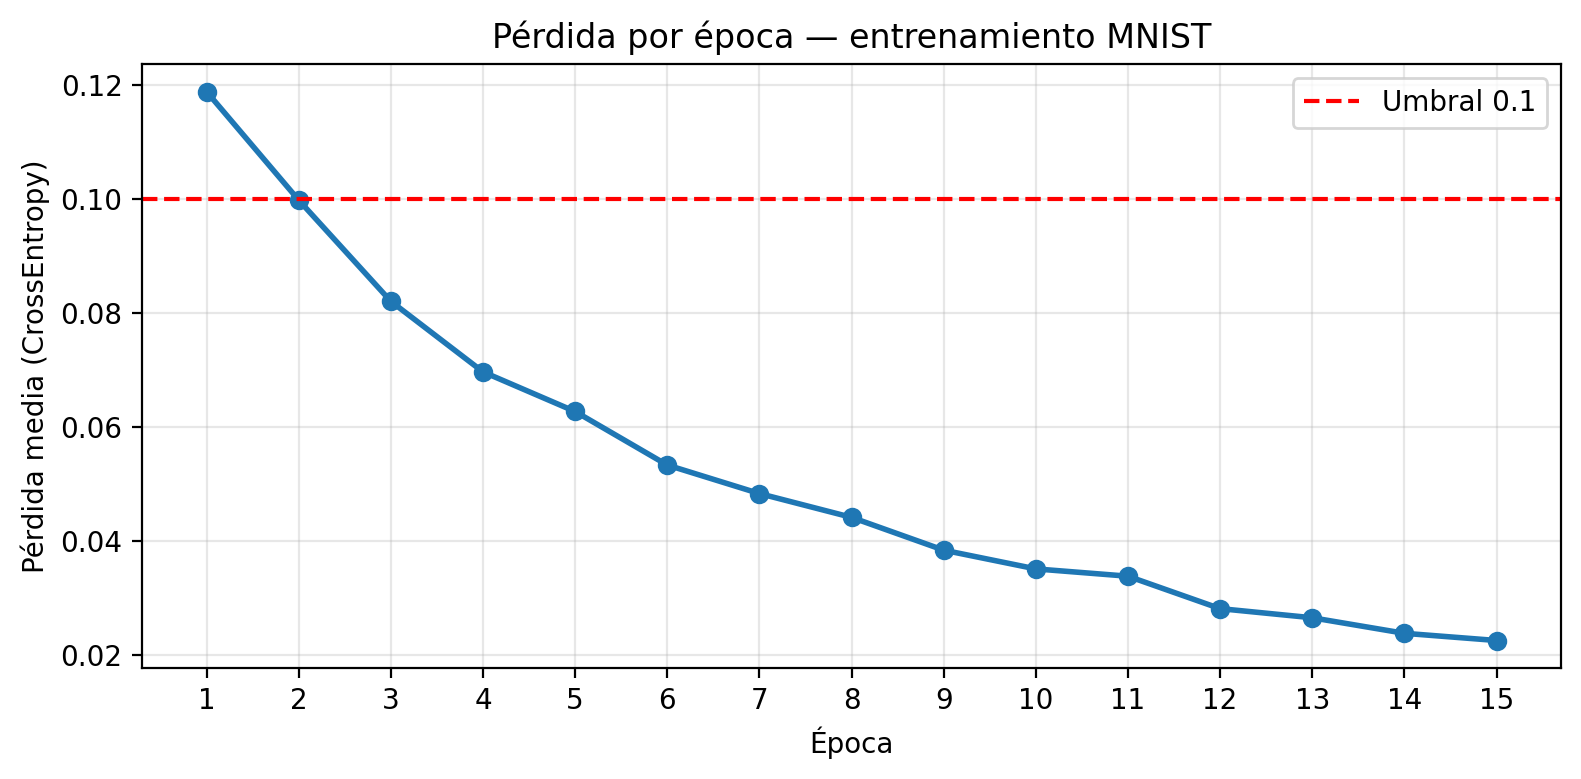

Pérdida final: 0.0226


In [21]:
import matplotlib.pyplot as plt

print_every = 40
steps = 0
epochs = 15
tasa_de_aprendizaje = 0.01

# TODO: redefine la configuración del optimizador usando la tasa de aprendizaje objetivo (1 punto)
optimizer = optim.SGD(model.parameters(), lr=tasa_de_aprendizaje, momentum=0.9)


# Listas para guardar la pérdida por época
epoch_losses = []

for e in range(epochs):
    running_loss = 0
    epoch_loss = 0
    n_batches = 0

    for images, labels in iter(trainloader):
        steps += 1
        n_batches += 1
        images.resize_(images.size()[0], 784)

        optimizer.zero_grad()

        # TODO: Pase frontal
        output = model(images)

        # TODO: Pérdida
        loss = criterion(output, labels)

        # TODO: Backpropagation
        loss.backward()

        # TODO: Actualizar pesos
        optimizer.step()

        running_loss += loss.item()
        epoch_loss += loss.item()

        if steps % print_every == 0:
            print("Epoch: {}/{}... ".format(e+1, epochs),
                  "Loss: {:.4f}".format(running_loss/print_every))
            running_loss = 0

    # Pérdida media de la época
    avg_epoch_loss = epoch_loss / n_batches
    epoch_losses.append(avg_epoch_loss)
    print(f"===== Epoch {e+1}/{epochs} — Loss media: {avg_epoch_loss:.4f} =====")

# Gráfica
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs+1), epoch_losses, marker='o', linewidth=2)
plt.xlabel('Época')
plt.ylabel('Pérdida media (CrossEntropy)')
plt.title('Pérdida por época — entrenamiento MNIST')
plt.grid(True, alpha=0.3)
plt.xticks(range(1, epochs+1))
plt.axhline(y=0.1, color='red', linestyle='--', label='Umbral 0.1')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Pérdida final: {epoch_losses[-1]:.4f}")

Epoch: 1/5...  Loss: 0.0915
Epoch: 1/5...  Loss: 0.0770
Epoch: 1/5...  Loss: 0.0640
Epoch: 1/5...  Loss: 0.0603
Epoch: 1/5...  Loss: 0.0653
Epoch: 1/5...  Loss: 0.0529
Epoch: 1/5...  Loss: 0.0626
Epoch: 1/5...  Loss: 0.1047
Epoch: 1/5...  Loss: 0.0950
Epoch: 1/5...  Loss: 0.0805
Epoch: 1/5...  Loss: 0.0717
Epoch: 1/5...  Loss: 0.0539
Epoch: 1/5...  Loss: 0.0589
Epoch: 1/5...  Loss: 0.0603
Epoch: 1/5...  Loss: 0.0529
Epoch: 1/5...  Loss: 0.0578
Epoch: 1/5...  Loss: 0.0784
Epoch: 1/5...  Loss: 0.0613
Epoch: 1/5...  Loss: 0.0735
Epoch: 1/5...  Loss: 0.0525
Epoch: 1/5...  Loss: 0.0905
Epoch: 1/5...  Loss: 0.0731
Epoch: 1/5...  Loss: 0.0764
===== Epoch 1/5 — Loss media: 0.0704 =====
Epoch: 2/5...  Loss: 0.0305
Epoch: 2/5...  Loss: 0.0714
Epoch: 2/5...  Loss: 0.0413
Epoch: 2/5...  Loss: 0.0480
Epoch: 2/5...  Loss: 0.0627
Epoch: 2/5...  Loss: 0.0510
Epoch: 2/5...  Loss: 0.0502
Epoch: 2/5...  Loss: 0.0586
Epoch: 2/5...  Loss: 0.0439
Epoch: 2/5...  Loss: 0.0477
Epoch: 2/5...  Loss: 0.0566
Epoch

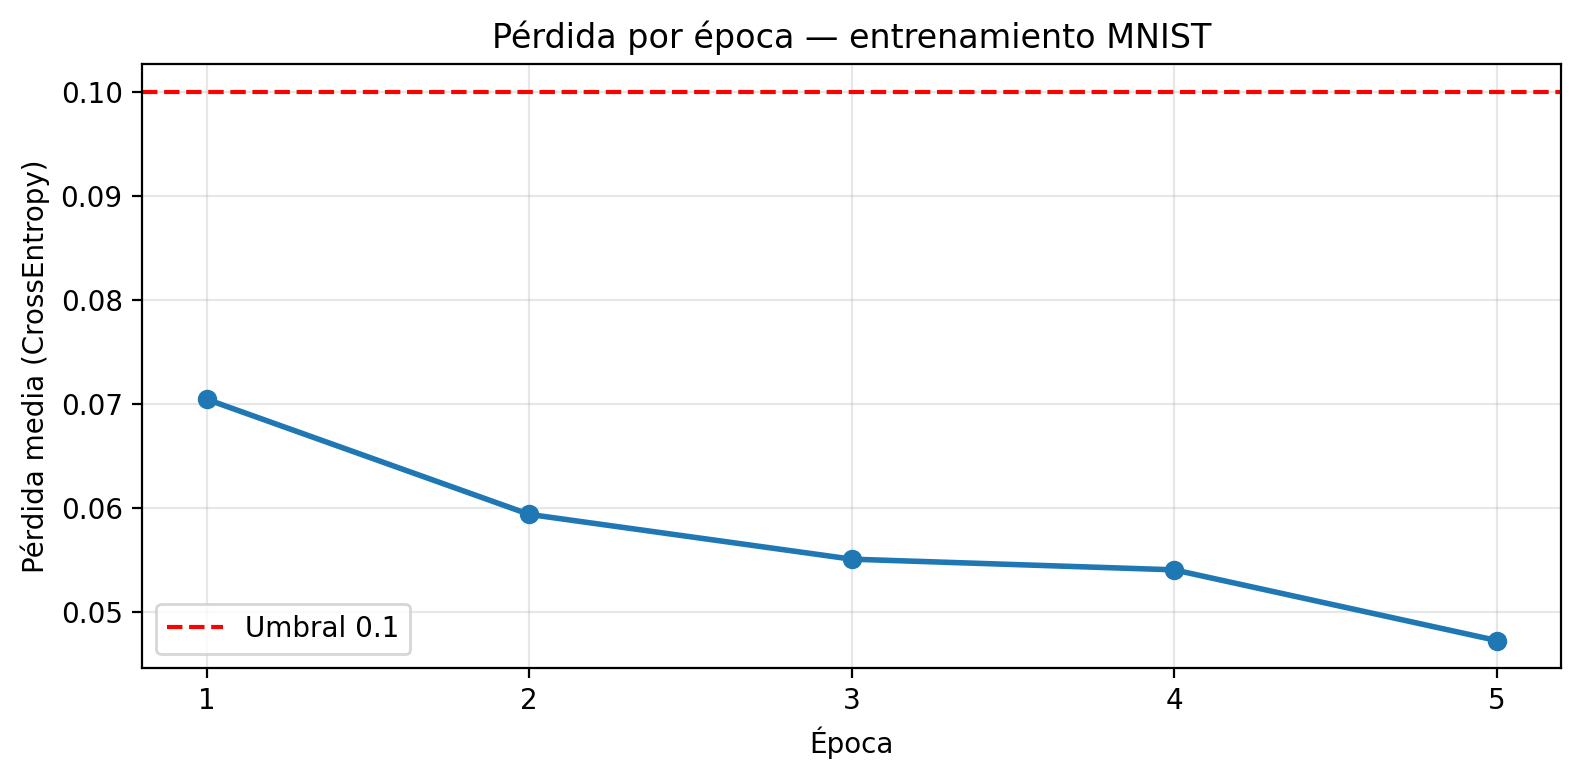

Pérdida final: 0.0473


In [22]:
import matplotlib.pyplot as plt

print_every = 40
steps = 0
epochs = 5
tasa_de_aprendizaje = 0.001

# TODO: redefine la configuración del optimizador usando la tasa de aprendizaje objetivo (1 punto)
optimizer = optim.Adam(model.parameters(), lr=tasa_de_aprendizaje)


# Listas para guardar la pérdida por época
epoch_losses = []

for e in range(epochs):
    running_loss = 0
    epoch_loss = 0
    n_batches = 0

    for images, labels in iter(trainloader):
        steps += 1
        n_batches += 1
        images.resize_(images.size()[0], 784)

        optimizer.zero_grad()

        # TODO: Pase frontal
        output = model(images)

        # TODO: Pérdida
        loss = criterion(output, labels)

        # TODO: Backpropagation
        loss.backward()

        # TODO: Actualizar pesos
        optimizer.step()

        running_loss += loss.item()
        epoch_loss += loss.item()

        if steps % print_every == 0:
            print("Epoch: {}/{}... ".format(e+1, epochs),
                  "Loss: {:.4f}".format(running_loss/print_every))
            running_loss = 0

    # Pérdida media de la época
    avg_epoch_loss = epoch_loss / n_batches
    epoch_losses.append(avg_epoch_loss)
    print(f"===== Epoch {e+1}/{epochs} — Loss media: {avg_epoch_loss:.4f} =====")

# Gráfica
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs+1), epoch_losses, marker='o', linewidth=2)
plt.xlabel('Época')
plt.ylabel('Pérdida media (CrossEntropy)')
plt.title('Pérdida por época — entrenamiento MNIST')
plt.grid(True, alpha=0.3)
plt.xticks(range(1, epochs+1))
plt.axhline(y=0.1, color='red', linestyle='--', label='Umbral 0.1')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Pérdida final: {epoch_losses[-1]:.4f}")